# .....................................................Data Dictionary...........................................................

### 1. age: age in years
### 2. sex: sex
###### 1 = male
###### 0 = female
### 3. cp: chest pain type
###### 0: typical angina
###### 1: atypical angina
###### 2: non-anginal pain
###### 3: asymptomatic
### 4. trestbps: resting blood pressure (in mm Hg on admission to the hospital)
### 5. chol: serum cholestoral in mg/dl
### 6. fbs: (fasting blood sugar > 120 mg/dl)
###### 1 = true;
###### 0 = false
#### 7. restecg: resting electrocardiographic results
###### 0: normal
###### 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
###### 2: showing probable or definite left ventricular hypertrophy by Estes' criteria
### 8. thalach: maximum heart rate achieved
### 9. exang: exercise induced angina
###### 1 = yes
###### 0 = no
### 10. oldpeak = ST depression induced by exercise relative to rest
### 11. slope: the slope of the peak exercise ST segment
###### 0: upsloping
###### 1: flat
###### 2: downsloping
### 12. ca: number of major vessels (0-3) colored by flourosopy
### 13. thal:
###### 0 = error (in the original dataset 0 maps to NaN's)
###### 1 = fixed defect
###### 2 = normal
###### 3 = reversable defect
### 14. target (the lable):
###### 0 = no disease,
###### 1 = disease

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (f1_score, roc_auc_score, accuracy_score, classification_report,
                            confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay, RocCurveDisplay)
warnings.filterwarnings('ignore')
pd.pandas.set_option('display.max_columns', None)
%matplotlib inline


In [2]:
data = pd.read_csv("heart.csv")
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
print("Total rows:", len(data))
print("Duplicate rows:", data.duplicated().sum())

Total rows: 1025
Duplicate rows: 723


In [4]:
data = data.drop_duplicates().reset_index(drop=True)

In [5]:
data.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [6]:
data.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

In [7]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.2 KB


In [9]:
cat_feat = []
for column in data.columns:
  if len(data[column].unique()) <= 5:
    cat_feat.append(column)
print(cat_feat)

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']


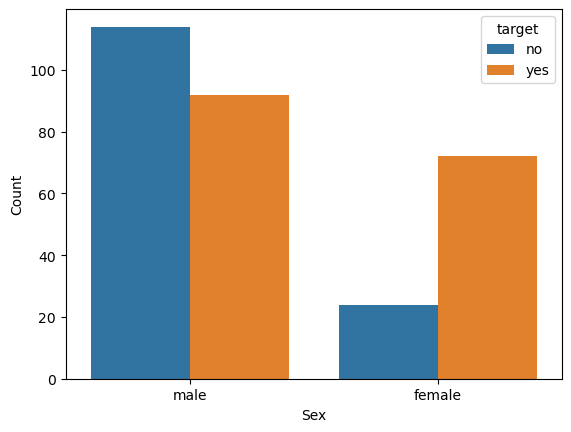

In [10]:
data2 = data.copy()
data2["sex"] = data["sex"].map({1 : "male", 0 : "female"})
data2["target"] = data["target"].map({1 : "yes", 0 : "no"})
sns.countplot(data = data2, x = "sex", hue = "target")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()


#### -More patients in the sample data are male.
#### -Females have higher rate of heart problem

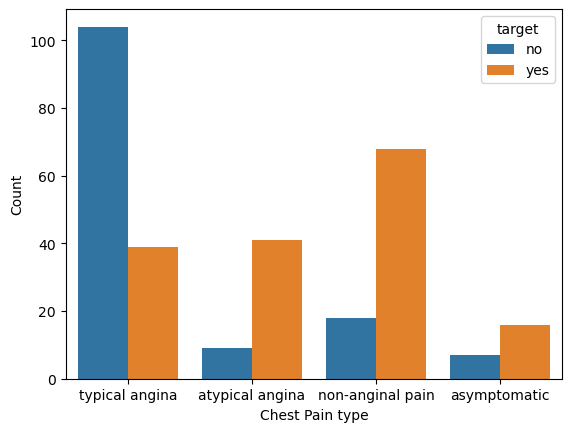

In [11]:
data2["cp"] = data2["cp"].map({0 : 'typical angina', 1 : 'atypical angina', 2 : "non-anginal pain", 3 : "asymptomatic"})
sns.countplot(data = data2, x = "cp", hue = "target")
plt.xlabel("Chest Pain type")
plt.ylabel("Count")
plt.show()

#### -Most of the patients are suffering from either typical or non-anginal pain whith more having typical angina pain
#### -Patients suffering from either atypical or non-angina pain are likely to have heart problem

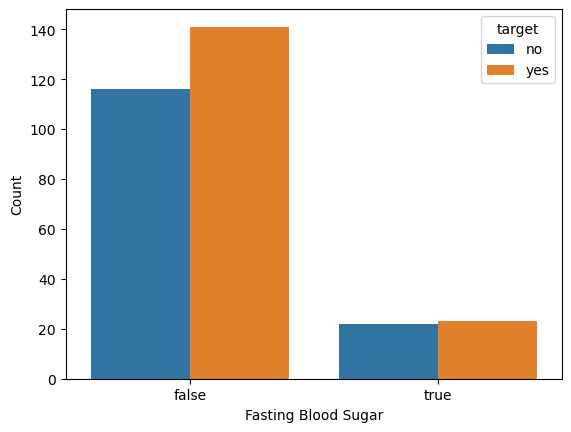

In [12]:
data2['fbs'] = data2["fbs"].map({0 : "false", 1 : "true"})
sns.countplot(data = data2, x = "fbs", hue = "target")
plt.xlabel("Fasting Blood Sugar")
plt.ylabel("Count")
plt.show()

##### -Patients with lower fasting blood sugar have higher population
##### -Patients having lower fasting blood sugar have higher tendency to suffer from heart condition

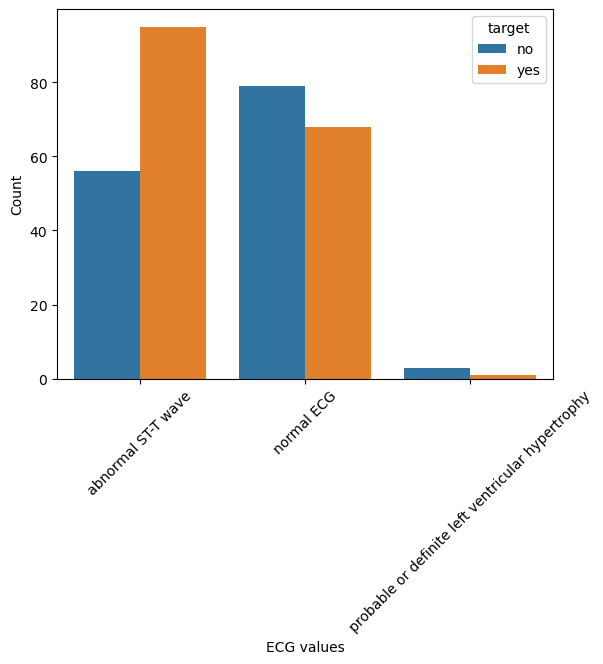

In [13]:
data2['restecg'] = data2["restecg"].map({0 : "normal ECG", 1 : "abnormal ST-T wave", 2 : "probable or definite left ventricular hypertrophy"})
sns.countplot(data = data2, x = "restecg", hue = "target")
plt.xlabel("ECG values")
plt.ylabel("Count")
plt.xticks(rotation = 45)
plt.show()

##### -Patients with left ventricular hypertrophy are the fewest with others having almost equal distribution
##### -Patients having abnormal ST-T  have the highest tendency of suffering from heart disease

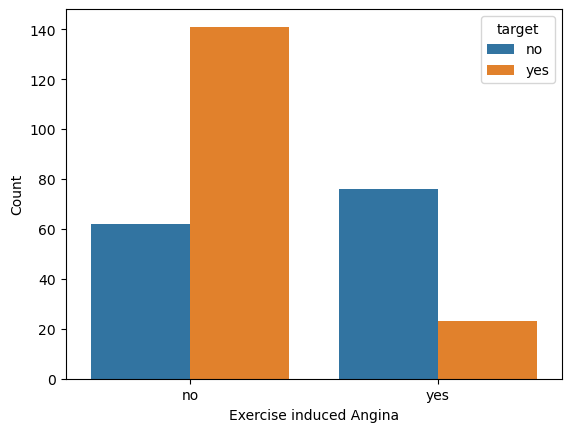

In [14]:
data2['exang'] = data2["exang"].map({0 : "no", 1 : "yes"})
sns.countplot(data = data2, x = "exang", hue = "target")
plt.xlabel("Exercise induced Angina")
plt.ylabel("Count")
plt.show()

##### -Most patients(65%) show no exercise induced angina
##### -Patients with no exercise induced angina had higer rate of suffering from heart condition

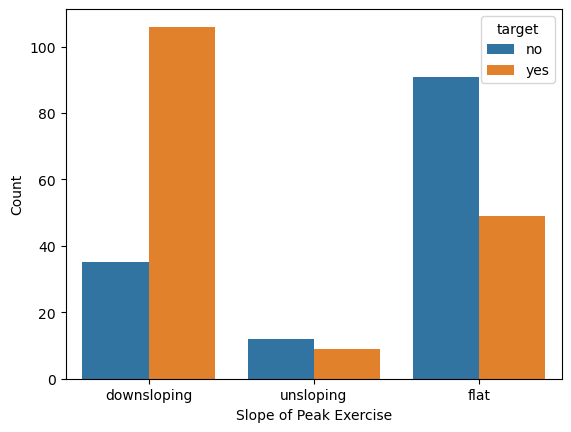

In [15]:
data2['slope'] = data2["slope"].map({0 : "unsloping", 1 : "flat", 2 : "downsloping"})
sns.countplot(data = data2, x = "slope", hue = "target")
plt.xlabel("Slope of Peak Exercise")
plt.ylabel("Count")
plt.show()

##### -Most patients have either downsloping or flat Slope of peak exercise

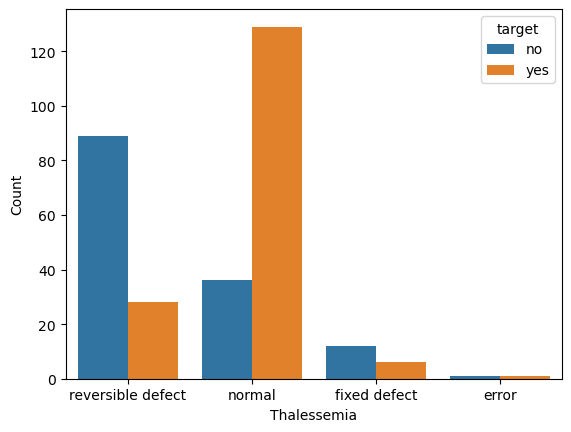

In [16]:
data2['thal'] = data2["thal"].map({0 : "error", 1 : "fixed defect", 2 : "normal", 3 : "reversible defect"})
sns.countplot(data = data2, x = "thal", hue = "target")
plt.xlabel("Thalessemia")
plt.ylabel("Count")
plt.show()

##### -Most patients have Thalassemia(reversible or fixed defect)
##### -Patients having thalassemia have lower chance of having heart problem (This is surprising)

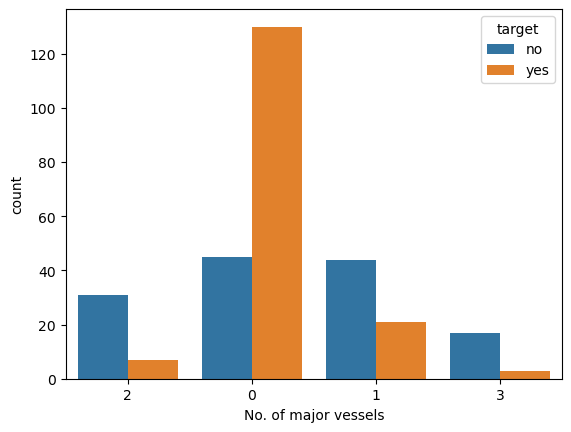

In [17]:
data2['ca'] = data2["ca"].map({0 : "0", 1 : "1", 2 : "2", 3 : "3"})
sns.countplot(data = data2, x = "ca", hue = "target")
plt.xlabel("No. of major vessels")
plt.ylabel("count")
plt.show()

##### -Patients having zero blood vessels have the highest population and also have high disease rate

In [18]:
cont_feat = []
for column in data.columns:
    if column not in cat_feat:
        cont_feat.append(column)
print(cont_feat)

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


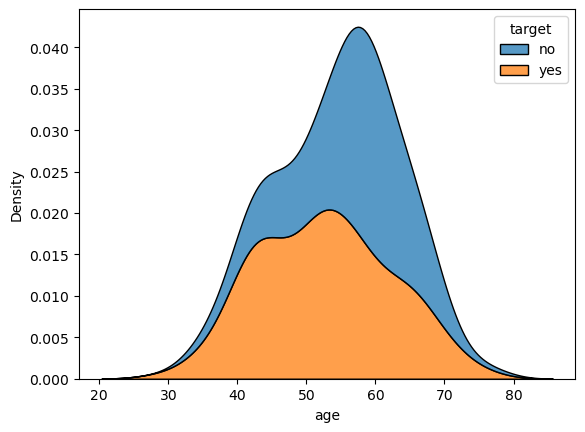

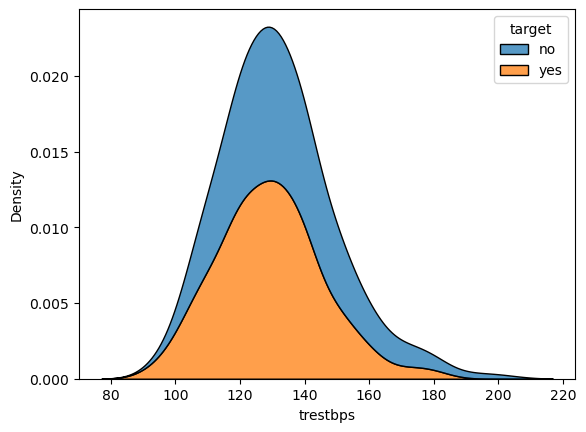

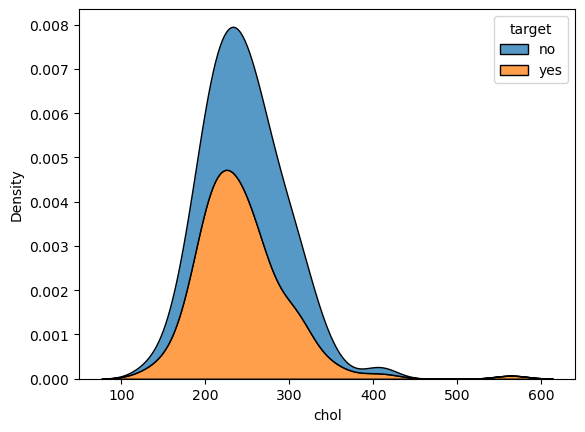

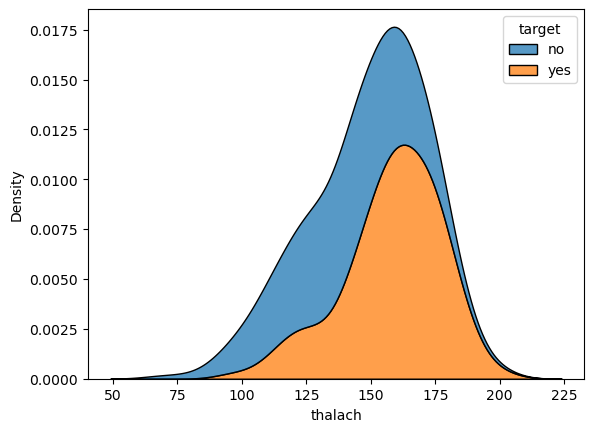

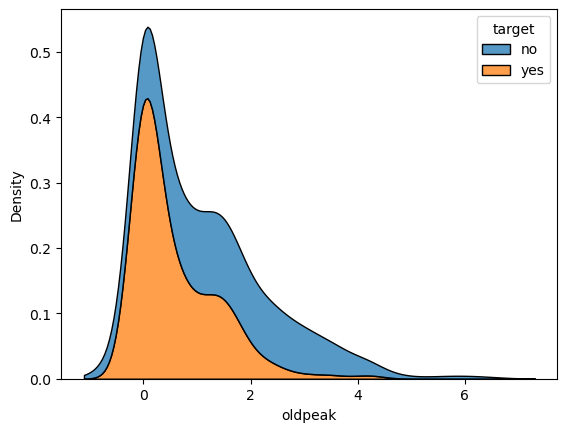

In [19]:
for feat in cont_feat:
  sns.kdeplot(data = data2, x = feat, hue = "target", multiple = "stack")
  plt.xlabel(feat)
  plt.ylabel("Density")
  plt.show()

### Age, Trestbps, and Chol are the most normally distributed while  thalach and oldpeak are left skewed and right skewed respectively

In [20]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

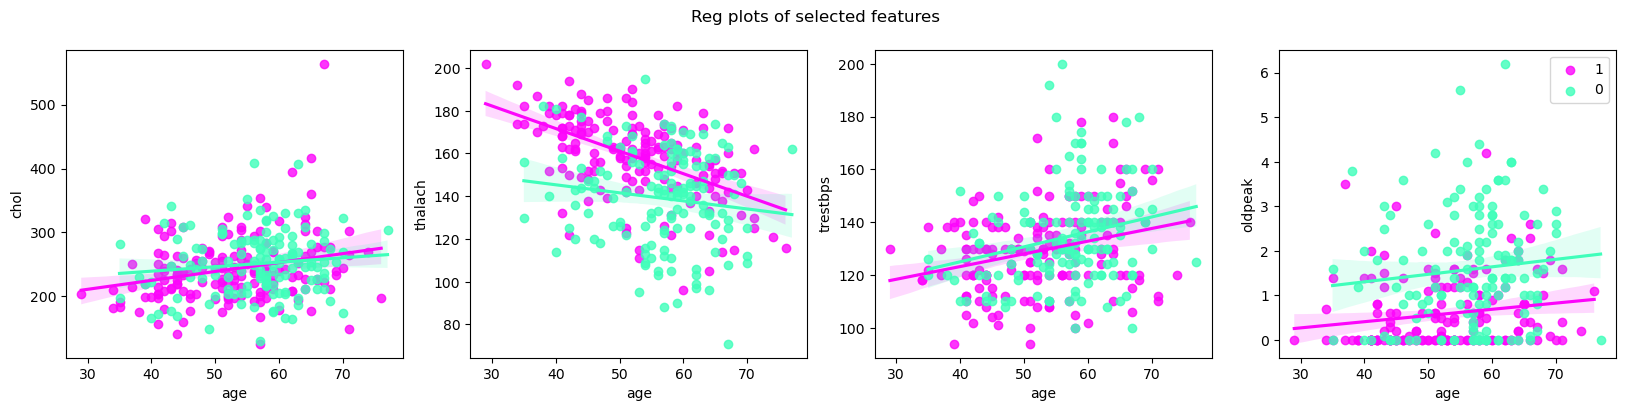

In [21]:
mypal = ["#FC05FB", "#FEAEFE", "#FCD2FC", "#F3FEFA", "#B4FFE4", "#3FFEBA"]
fig, ax = plt.subplots(1,4, figsize=(20, 4))
sns.regplot(data=data[data['target'] ==1], x='age', y='chol', ax = ax[0], color=mypal[0], label='1')
sns.regplot(data=data[data['target'] ==0], x='age', y='chol', ax = ax[0], color=mypal[5], label='0')
sns.regplot(data=data[data['target'] ==1], x='age', y='thalach', ax = ax[1], color=mypal[0], label='1')
sns.regplot(data=data[data['target'] ==0], x='age', y='thalach', ax = ax[1], color=mypal[5], label='0')
sns.regplot(data=data[data['target'] ==1], x='age', y='trestbps', ax = ax[2], color=mypal[0], label='1')
sns.regplot(data=data[data['target'] ==0], x='age', y='trestbps', ax = ax[2], color=mypal[5], label='0')
sns.regplot(data=data[data['target'] ==1], x='age', y='oldpeak', ax = ax[3], color=mypal[0], label='1')
sns.regplot(data=data[data['target'] ==0], x='age', y='oldpeak', ax = ax[3], color=mypal[5], label='0')
plt.suptitle('Reg plots of selected features')
plt.legend();
plt.show()

##### Except maximum_heart_rate_achieved, the others are positively and linearly related with age(oldpeak(st_depression) is kind of weak)
##### Younger patients with higher thalach(max_heart_rate_achieved) are more likely to have a heart condition

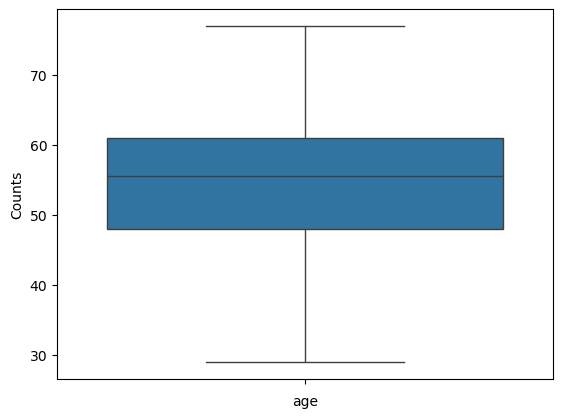

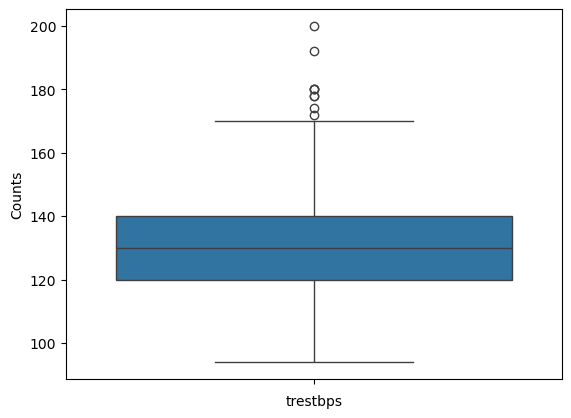

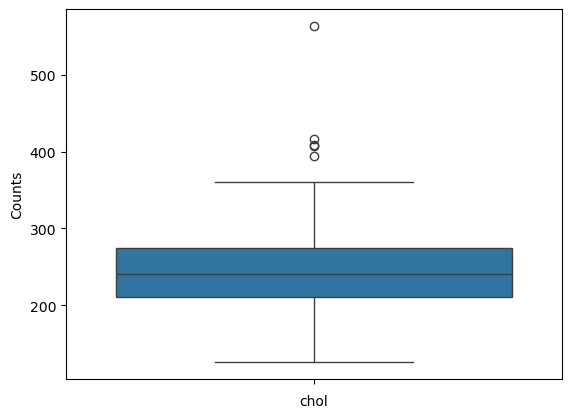

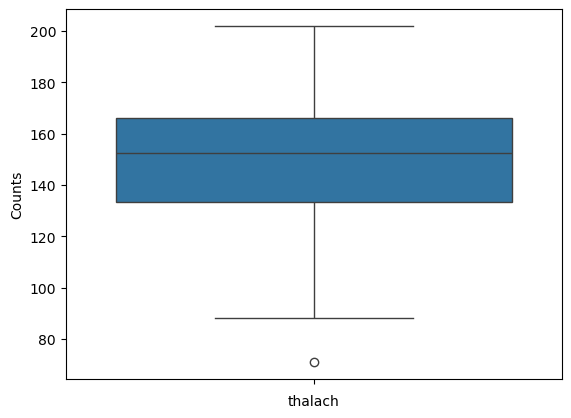

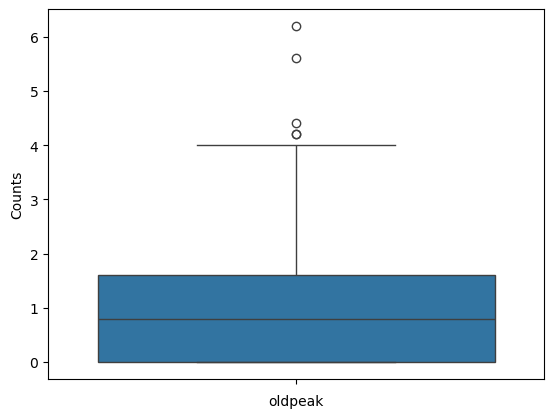

In [22]:
for feat in cont_feat:
  data2 = data.copy()
  sns.boxplot(data2[feat])
  plt.xlabel(feat)
  plt.ylabel("Counts")
  plt.show()

## -All except Age has no count of outliers.

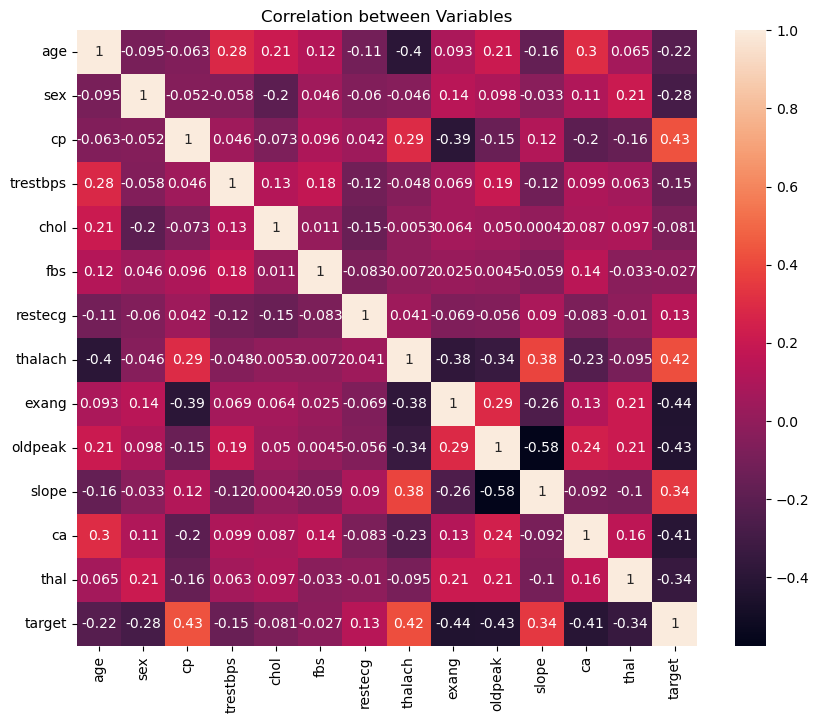

In [23]:
plt.figure(figsize = (10, 8))
sns.heatmap(data[data.columns].corr(), annot = True)
plt.title("Correlation between Variables")
plt.show()

## This heatmap shows that there is no colinearity between the independent variables

In [24]:
continuous_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
outlier_summary = []
for col in continuous_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    flagged = (data[col] < lower) | (data[col] > upper)
    outlier_summary.append({
        "Feature": col,
        "Minimum": data[col].min(),
        "Maximum": data[col].max(),
        "Lower IQR Bound": round(lower, 2),
        "Upper IQR Bound": round(upper, 2),
        "Outlier Count": int(flagged.sum()),
        "Outlier %": round(flagged.mean() * 100, 2)
    })
summary = pd.DataFrame(outlier_summary)
summary

,Feature,Minimum,Maximum,Lower IQR Bound,Upper IQR Bound,Outlier Count,Outlier %
0,age,29.0,77.0,28.50,80.50,0,0.00
1,trestbps,94.0,200.0,90.00,170.00,9,2.98
2,chol,126.0,564.0,115.38,370.38,5,1.66
3,thalach,71.0,202.0,84.12,215.12,1,0.33
4,oldpeak,0.0,6.2,-2.40,4.00,5,1.66


In [25]:
print(data.shape)
print(data[continuous_cols].min())
print(data[continuous_cols].max())

(302, 14)
age          29.0
trestbps     94.0
chol        126.0
thalach      71.0
oldpeak       0.0
dtype: float64
age          77.0
trestbps    200.0
chol        564.0
thalach     202.0
oldpeak       6.2
dtype: float64


In [26]:
for col in continuous_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    flagged = data[(data[col] < lower) | (data[col] > upper)]
    print(f"\n{col}: {len(flagged)} flagged records")
    if flagged.empty:
        print("No outliers detected")
    else:
        print(flagged[[col, "target"]].to_string(index=True))


age: 0 flagged records
No outliers detected

trestbps: 9 flagged records
     trestbps  target
28        180       0
44        178       0
76        174       0
112       180       1
124       192       0
142       200       0
226       172       1
248       180       0
271       178       1

chol: 5 flagged records
     chol  target
104   417       1
128   564       1
144   409       0
183   394       1
260   407       0

thalach: 1 flagged records
     thalach  target
188       71       0

oldpeak: 5 flagged records
     oldpeak  target
6        4.4       0
13       4.2       0
51       5.6       0
63       6.2       0
271      4.2       1


In [27]:
for col in continuous_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    flagged = data[(data[col] < lower) | (data[col] > upper)]
    print(f"\n{col}: lower = {lower:.2f}, upper = {upper:.2f}")
    print(flagged[[col, "target"]].to_string(index=True))


age: lower = 28.50, upper = 80.50
Empty DataFrame
Columns: [age, target]
Index: []

trestbps: lower = 90.00, upper = 170.00
     trestbps  target
28        180       0
44        178       0
76        174       0
112       180       1
124       192       0
142       200       0
226       172       1
248       180       0
271       178       1

chol: lower = 115.38, upper = 370.38
     chol  target
104   417       1
128   564       1
144   409       0
183   394       1
260   407       0

thalach: lower = 84.12, upper = 215.12
     thalach  target
188       71       0

oldpeak: lower = -2.40, upper = 4.00
     oldpeak  target
6        4.4       0
13       4.2       0
51       5.6       0
63       6.2       0
271      4.2       1


### The IQR method was used to identify potential outliers in the numerical features.
### Since extreme medical measurements may represent genuine patient conditions, the observations were retained rather than automatically removed. 
### This preserves potentially useful clinical information for model training.

In [28]:
ind_var = []
for column in data.columns:
    if column == "target":
        pass
    else:
        ind_var.append(column)

In [29]:
X = data.drop(columns="target")
y = data["target"].astype(int)

In [30]:
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,68,0,2,120,211,0,0,115,0,1.5,1,0,2
298,44,0,2,108,141,0,1,175,0,0.6,1,0,2
299,52,1,0,128,255,0,1,161,1,0.0,2,1,3
300,59,1,3,160,273,0,0,125,0,0.0,2,0,2


In [31]:
# 1. Split first, before any scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0
)

In [32]:
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

target_column = "target"

In [33]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [34]:
LogisticRegression()

LogisticRegression()

In [35]:
models = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=3000,
            random_state=42
        ),
        {
            "classifier__C": [0.01, 0.1, 1, 10, 100],
            "classifier__class_weight": [None, "balanced"]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(
            random_state=42
        ),
        {
            "classifier__max_depth": [3, 5, 7, 10, None],
            "classifier__min_samples_leaf": [1, 3, 5, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [4, 6, 10, None],
            "classifier__min_samples_leaf": [1, 2, 5],
            "classifier__class_weight": [None, "balanced"]
        }
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [36]:
import joblib


Training: Logistic Regression
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Mean CV ROC-AUC: 0.9211
Test accuracy:   0.9344
Test precision:  0.9394
Test recall:     0.9394
Test F1-score:   0.9394
Test ROC-AUC:    0.9426

Classification report:
              precision    recall  f1-score   support

  No disease       0.93      0.93      0.93        28
     Disease       0.94      0.94      0.94        33

    accuracy                           0.93        61
   macro avg       0.93      0.93      0.93        61
weighted avg       0.93      0.93      0.93        61



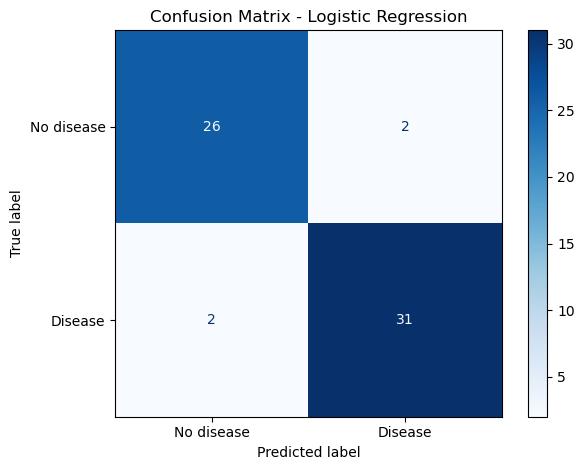


Training: Decision Tree
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 10}
Mean CV ROC-AUC: 0.8657
Test accuracy:   0.8689
Test precision:  0.8571
Test recall:     0.9091
Test F1-score:   0.8824
Test ROC-AUC:    0.9037

Classification report:
              precision    recall  f1-score   support

  No disease       0.88      0.82      0.85        28
     Disease       0.86      0.91      0.88        33

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



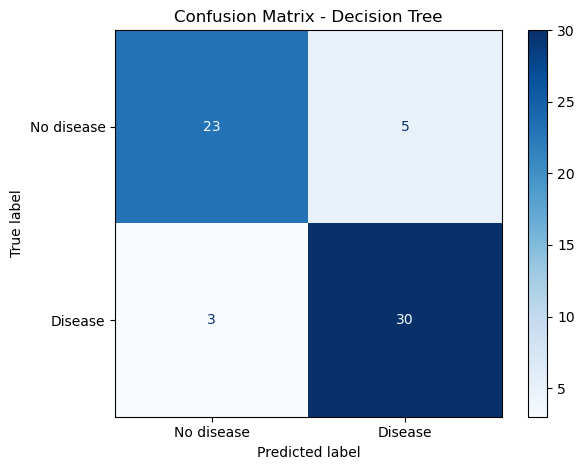


Training: Random Forest
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Mean CV ROC-AUC: 0.9221
Test accuracy:   0.8689
Test precision:  0.9032
Test recall:     0.8485
Test F1-score:   0.8750
Test ROC-AUC:    0.9491

Classification report:
              precision    recall  f1-score   support

  No disease       0.83      0.89      0.86        28
     Disease       0.90      0.85      0.88        33

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



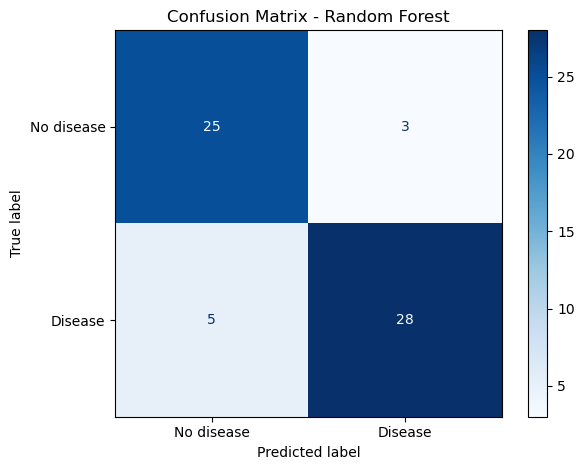

In [37]:
results = []
fitted_models = {}
test_probabilities = {}
test_predictions = {}

for model_name, (classifier, parameter_grid) in models.items():

    print("\n" + "=" * 65)
    print("Training:", model_name)
    print("=" * 65)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    search.fit(X_train, y_train)

    best_pipeline = search.best_estimator_

    # The test set is used only after training and tuning.
    y_pred = best_pipeline.predict(X_test)
    y_prob = best_pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    auc = roc_auc_score(y_test, y_prob)

    print("Best parameters:", search.best_params_)
    print(f"Mean CV ROC-AUC: {search.best_score_:.4f}")
    print(f"Test accuracy:   {accuracy:.4f}")
    print(f"Test precision:  {precision:.4f}")
    print(f"Test recall:     {recall:.4f}")
    print(f"Test F1-score:   {f1:.4f}")
    print(f"Test ROC-AUC:    {auc:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No disease", "Disease"],
        zero_division=0
    ))
    fitted_models[model_name] = best_pipeline
    test_predictions[model_name] = y_pred
    test_probabilities[model_name] = y_prob
    results.append({
        "Model": model_name,
        "Best_CV_ROC_AUC": search.best_score_,
        "Test_Accuracy": accuracy,
        "Test_Precision": precision,
        "Test_Recall": recall,
        "Test_F1": f1,
        "Test_ROC_AUC": auc,
        "Best_Parameters": str(search.best_params_)
    })

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No disease", "Disease"]
    )

    display.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

In [38]:
results_df = pd.DataFrame(results).sort_values(
    by="Best_CV_ROC_AUC",
    ascending=False
)

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)
print(results_df.to_string(index=False, float_format="%.4f"))


FINAL MODEL COMPARISON
              Model  Best_CV_ROC_AUC  Test_Accuracy  Test_Precision  Test_Recall  Test_F1  Test_ROC_AUC                                                                                                                          Best_Parameters
      Random Forest           0.9221         0.8689          0.9032       0.8485   0.8750        0.9491 {'classifier__class_weight': 'balanced', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Logistic Regression           0.9211         0.9344          0.9394       0.9394   0.9394        0.9426                                                                           {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
      Decision Tree           0.8657         0.8689          0.8571       0.9091   0.8824        0.9037                                       {'classifier__class_weight': None, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 10}


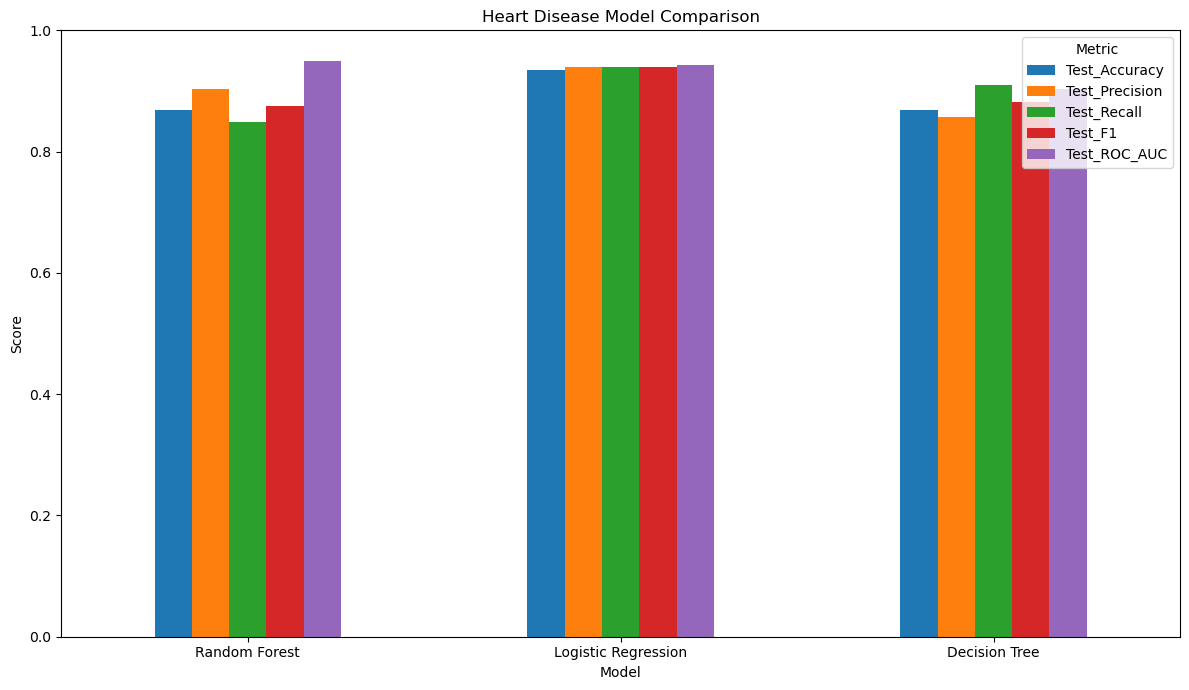

In [39]:
metric_columns = [
    "Test_Accuracy",
    "Test_Precision",
    "Test_Recall",
    "Test_F1",
    "Test_ROC_AUC"
]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 7),
    ylim=(0, 1)
)
plt.title("Heart Disease Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

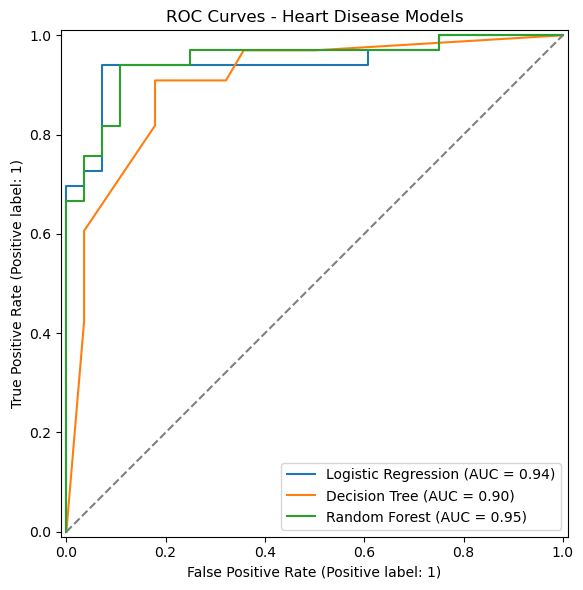

In [40]:
fig, ax = plt.subplots(figsize=(8, 6))

for model_name in models:
    RocCurveDisplay.from_predictions(
        y_test,
        test_probabilities[model_name],
        name=model_name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
ax.set_title("ROC Curves - Heart Disease Models")
plt.tight_layout()
plt.show()

In [41]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = fitted_models[best_model_name]

In [42]:
best_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=6,
                                        min_samples_leaf=2, n_estimators=200,
                                        n_jobs=1, random_state=42))])

In [43]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = fitted_models[best_model_name]

joblib.dump(best_pipeline, "best_heart_disease_pipeline.joblib")

print("Best model:", best_model_name)
print("Best pipeline saved successfully.")

Best model: Random Forest
Best pipeline saved successfully.
